# Tema 2 Machine Learning - Sentiment Analysis
## Mandescu Victor-Ioan 342C4

In [1]:
%pip install tensorflow
%pip install matplotlib Pillow scikit-learn seaborn spacy gensim nltk pandas tqdm
%pip install fasttext
%pip install transformers
!python -m spacy download ro_core_news_sm

import numpy as np
import os
import matplotlib.pyplot as plt
import random
import seaborn as sns
import spacy
import gensim
import string
import re
import pandas as pd
import nltk

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D
from tensorflow.keras.initializers import Constant
from tensorflow.keras.optimizers import Adam

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split

from collections import defaultdict, Counter
from tqdm import tqdm

from nltk.corpus import stopwords
from nltk.util import ngrams
from nltk.tokenize import word_tokenize

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 31.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('ro_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import unicodedata
import re

def remove_diacritics(text):
    text = text.lower()
    text = re.sub(r"\bsînt\w*", "sunt", text)
    text = text.replace("ş", "s").replace("ș", "s")
    text = text.replace("ţ", "t").replace("ț", "t")
    text = re.sub(r"(?<=[a-z0-9])î(?=[a-z0-9])", "â", text)
    text_clean = unicodedata.normalize('NFKD', text).encode('ASCII', 'ignore').decode('utf-8')

    return text_clean.lower()

In [3]:
nlp = spacy.load("ro_core_news_sm")
stop_words_default = nlp.Defaults.stop_words
stop_words_filtered = {remove_diacritics(w) for w in stop_words_default}

## 1. Exploratory Data Analysis

In [4]:
print(list(stop_words_default)[:30])
print(list(stop_words_filtered)[:30])

['același', 'cît', 'aceea', 'datorită', 'sa-ti', 'incit', 'alte', 'nicidecum', 'catre', 'unor', 'pot', 'cineva', 'cîţi', 'dintr-', 'mulți', 'ei', 'neîncetat', 'toată', 'ala', 'cit', 'sunteți', 'inapoi', 'acestei', 'multi', 'altceva', 'unui', 'toate', 'dar', 'ati', 'p']
['aceea', 'sa-ti', 'incit', 'alte', 'nicidecum', 'catre', 'unor', 'pot', 'cineva', 'dintr-', 'ei', 'ala', 'cit', 'inapoi', 'multi', 'acestei', 'altceva', 'unui', 'toate', 'incat', 'fiti', 'dar', 'ati', 'p', 'prima', 'vi', 'se', 'bine', 'ceva', 'ea']


In [5]:
train_loader = pd.read_csv('train.csv')
test_loader = pd.read_csv('test.csv')

In [6]:
train_loader.head()

,index,text,label
0,0,acest document mi-a deschis cu adevarat ochii ...,1
1,1,tine mancarea rece. ce altceva ii mai trebuie?...,1
2,2,excelent\nrecomand!,1
3,3,"ca un rocker imbatranit, acest film mentioneaz...",1
4,4,"ei bine, a facut o groaza veche si foarte intu...",1


In [7]:
test_loader.head()

,Unnamed: 0,text,label
0,0,am vazut recent episoadele 1-4 si acum nu pot ...,1
1,1,anii cei mai buni ai vietii noastre capteaza p...,1
2,2,"aceasta apartine in clasa lor superioara, desi...",1
3,3,lucrare stralucitoare. actorii minunati se diz...,1
4,4,oamenii par sa se astepte la citizen kane aici...,1


In [8]:
test_loader.rename(columns={test_loader.columns[0]: 'index'}, inplace=True)
test_loader.head()

,index,text,label
0,0,am vazut recent episoadele 1-4 si acum nu pot ...,1
1,1,anii cei mai buni ai vietii noastre capteaza p...,1
2,2,"aceasta apartine in clasa lor superioara, desi...",1
3,3,lucrare stralucitoare. actorii minunati se diz...,1
4,4,oamenii par sa se astepte la citizen kane aici...,1


In [9]:
train_loader.shape

(17941, 3)

In [10]:
test_loader.shape

(11005, 3)

In [11]:
train_loader.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17941 entries, 0 to 17940
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   index   17941 non-null  int64 
 1   text    17651 non-null  object
 2   label   17941 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 420.6+ KB


In [12]:
test_loader.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11005 entries, 0 to 11004
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   index   11005 non-null  int64 
 1   text    11005 non-null  object
 2   label   11005 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 258.1+ KB


In [13]:
train_loader.isnull().sum()

,0
index,0
text,290
label,0


In [14]:
test_loader.isnull().sum()

,0
index,0
text,0
label,0


In [15]:
train_loader.dropna(subset=['text'], inplace=True)
train_loader.isnull().sum()

,0
index,0
text,0
label,0


In [16]:
train_loader.duplicated().sum()

np.int64(0)

In [17]:
test_loader.duplicated().sum()

np.int64(0)

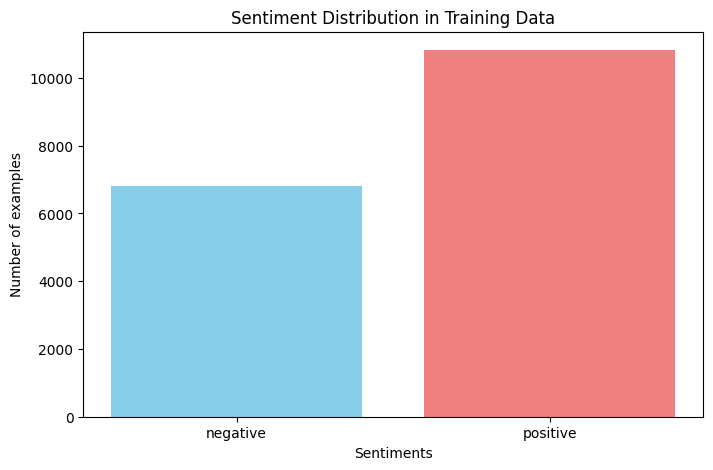

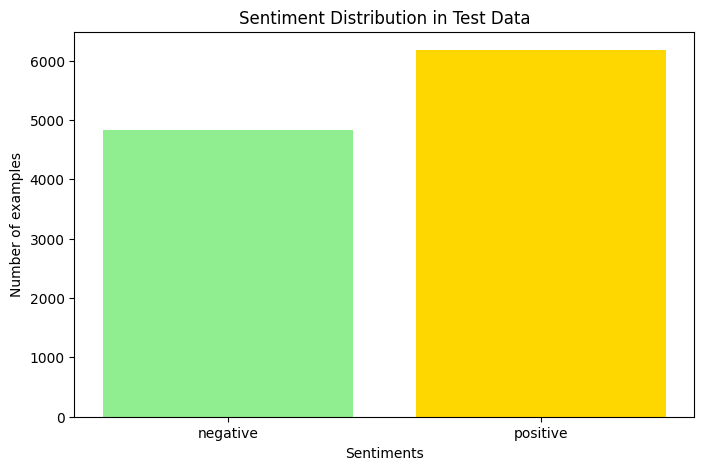

In [18]:
labels = ["negative", "positive"]
values_train = train_loader['label'].value_counts().sort_index().values
values_test = test_loader['label'].value_counts().sort_index().values

plt.figure(figsize=(8, 5))
plt.bar(labels, values_train, color=['skyblue', 'lightcoral'])
plt.xlabel('Sentiments')
plt.ylabel('Number of examples')
plt.title('Sentiment Distribution in Training Data')
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(labels, values_test, color=['lightgreen', 'gold'])
plt.xlabel('Sentiments')
plt.ylabel('Number of examples')
plt.title('Sentiment Distribution in Test Data')
plt.show()

In [19]:
from collections import Counter

pos_counter = Counter()
neg_counter = Counter()

for text in train_loader[train_loader['label'] == 1]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop_words_filtered and word.isalpha():
            clean_words.append(word)

    pos_counter.update(clean_words)

for text in train_loader[train_loader['label'] == 0]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop_words_filtered and word.isalpha():
            clean_words.append(word)

    neg_counter.update(clean_words)

print(pos_counter.most_common(10))
print(neg_counter.most_common(10))


[('film', 7712), ('filmul', 2231), ('vazut', 2093), ('bun', 1990), ('excelent', 1351), ('filme', 1280), ('recomand', 1250), ('trebuie', 1154), ('cred', 1107), ('facut', 1057)]
[('film', 6887), ('filmul', 1981), ('rau', 1525), ('vazut', 1471), ('lucru', 1415), ('decat', 1207), ('filme', 1185), ('facut', 1124), ('exista', 1045), ('cred', 1011)]


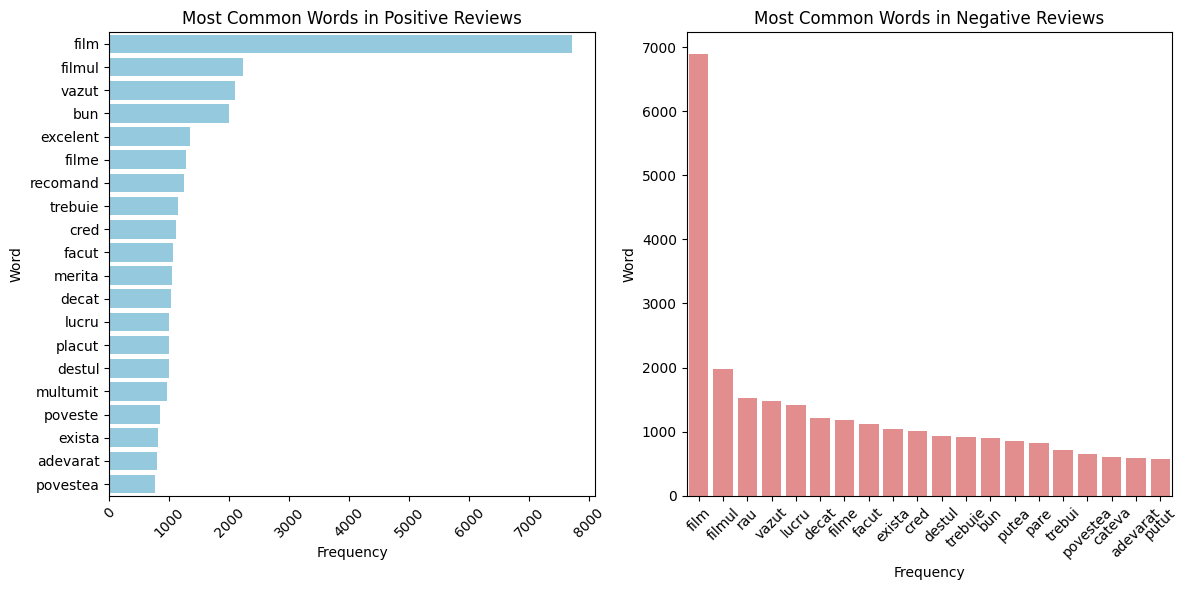

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

common_pos = pos_counter.most_common(20)
common_neg = neg_counter.most_common(20)

sns.barplot(x=[x[1] for x in common_pos], y=[x[0] for x in common_pos], ax=ax[0], color='skyblue')
ax[0].set_title('Most Common Words in Positive Reviews')
ax[0].set_xlabel('Frequency')
ax[0].set_ylabel('Word')
ax[0].tick_params(axis='x', labelrotation=45)

sns.barplot(x=[x[0] for x in common_neg], y=[x[1] for x in common_neg], ax=ax[1], color='lightcoral')
ax[1].set_title('Most Common Words in Negative Reviews')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Word')
ax[1].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()


In [21]:
pos_counter = Counter()
neg_counter = Counter()

for text in test_loader[test_loader['label'] == 1]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop_words_filtered and word.isalpha():
            clean_words.append(word)

    pos_counter.update(clean_words)

for text in test_loader[test_loader['label'] == 0]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop_words_filtered and word.isalpha():
            clean_words.append(word)

    neg_counter.update(clean_words)

print(pos_counter.most_common(10))
print(neg_counter.most_common(10))

[('film', 6608), ('filmul', 1824), ('vazut', 1613), ('filme', 1072), ('bun', 1058), ('trebuie', 1030), ('lucru', 1009), ('cred', 905), ('decat', 880), ('facut', 877)]
[('film', 6341), ('filmul', 1551), ('rau', 1425), ('lucru', 1335), ('vazut', 1219), ('filme', 1006), ('decat', 999), ('exista', 985), ('facut', 969), ('trebuie', 854)]


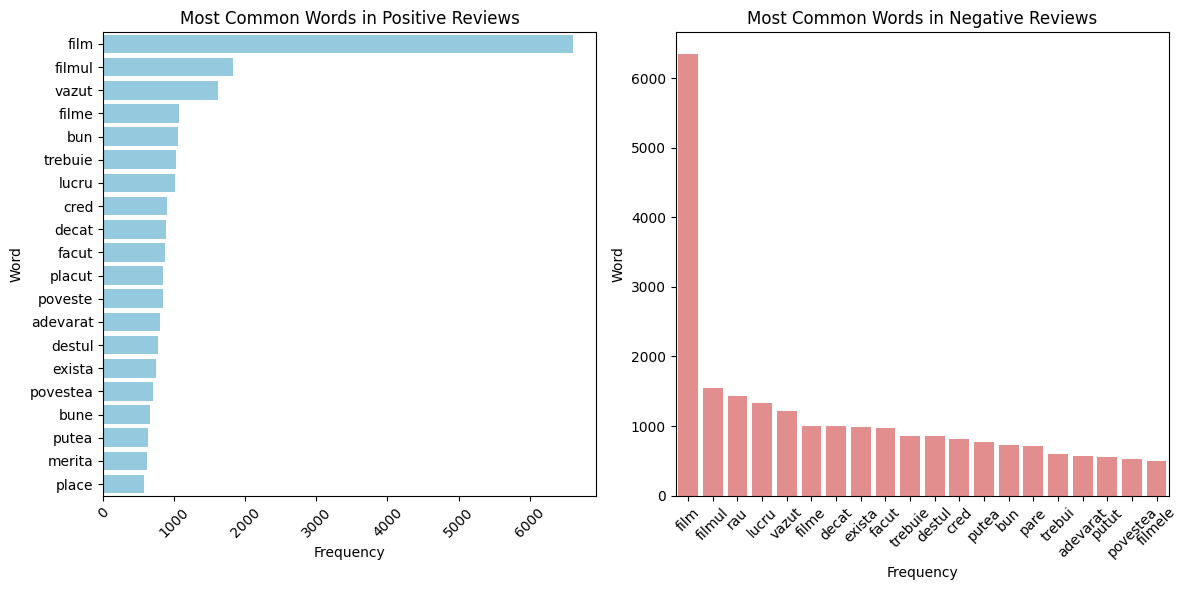

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

common_pos = pos_counter.most_common(20)
common_neg = neg_counter.most_common(20)

sns.barplot(x=[x[1] for x in common_pos], y=[x[0] for x in common_pos], ax=ax[0], color='skyblue')
ax[0].set_title('Most Common Words in Positive Reviews')
ax[0].set_xlabel('Frequency')
ax[0].set_ylabel('Word')
ax[0].tick_params(axis='x', labelrotation=45)

sns.barplot(x=[x[0] for x in common_neg], y=[x[1] for x in common_neg], ax=ax[1], color='lightcoral')
ax[1].set_title('Most Common Words in Negative Reviews')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Word')
ax[1].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

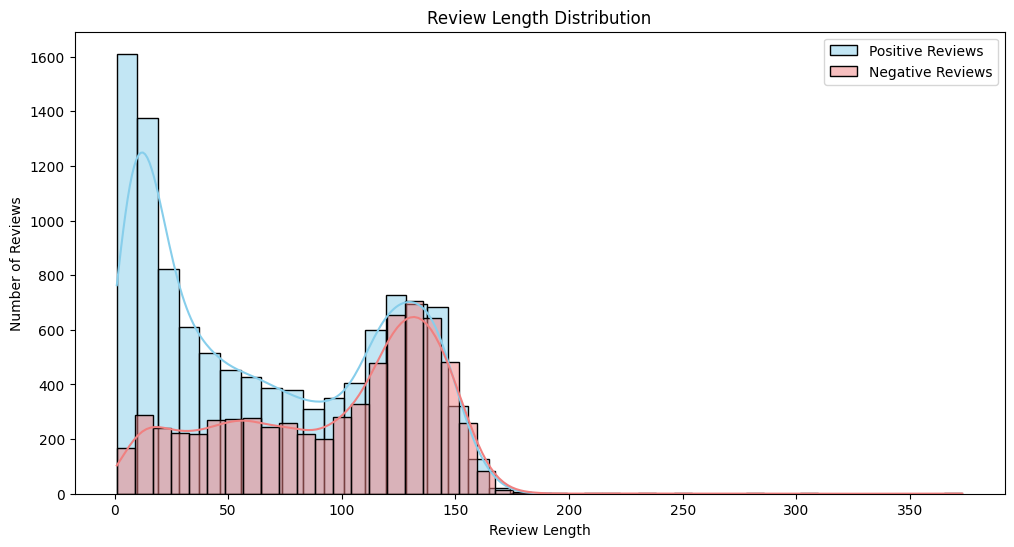

In [23]:
pos_counter = Counter()
neg_counter = Counter()

for text in train_loader[train_loader['label'] == 1]['text'].fillna(''):
  length = len(text.split())
  pos_counter.update([length])

for text in train_loader[train_loader['label'] == 0]['text'].fillna(''):
  length = len(text.split())
  neg_counter.update([length])

pos_lengths = list(pos_counter.elements())
neg_lengths = list(neg_counter.elements())

plt.figure(figsize=(12, 6))

sns.histplot(pos_lengths, color='skyblue', label='Positive Reviews', kde=True)
sns.histplot(neg_lengths, color='lightcoral', label='Negative Reviews', kde=True)

plt.title('Review Length Distribution')
plt.xlabel('Review Length')
plt.ylabel('Number of Reviews')
plt.legend()

plt.show()

## 2. Tokenize and Embedding

In [28]:
import nltk
from nltk.tokenize import word_tokenize
import re

nltk.download('punkt_tab')

clean_pattern = re.compile(r"[^a-z\s]")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = remove_diacritics(text)
    text = clean_pattern.sub(" ", text)

    tokens = word_tokenize(text)
    tokens = [token for token in tokens if token not in stop_words_filtered and len(token) > 1]

    return " ".join(tokens)


def clean_dataset(dataset, text_field, new_text_field_name):
    df = dataset.copy()

    df[new_text_field_name] = df[text_field].apply(clean_text)

    df = df[df[new_text_field_name].str.strip() != '']

    return df.reset_index(drop=True)

train_loader = clean_dataset(train_loader, 'text', 'text_clean')
test_loader = clean_dataset(test_loader, 'text', 'text_clean')

print(train_loader[['text', 'text_clean']].head())

                                                text  \
0  acest document mi-a deschis cu adevarat ochii ...   
1  tine mancarea rece. ce altceva ii mai trebuie?...   
2                                excelent\nrecomand!   
3  ca un rocker imbatranit, acest film mentioneaz...   
4  ei bine, a facut o groaza veche si foarte intu...   

                                          text_clean  
0  document deschis adevarat ochii oamenii afara ...  
1  mancarea rece trebuie frigiderul an utilizare ...  
2                                  excelent recomand  
3  rocker imbatranit film mentioneaza heep and qu...  
4  facut groaza veche intunecata casa setare incl...  


In [30]:
nlp = spacy.load("ro_core_news_sm", disable=["ner", "parser", "tagger", "lemmatizer"])

def tokenize(text_field):
    tokenized_list = []
    for doc in nlp.pipe(text_field.astype(str), batch_size=1000):
      tokens = [token.text for token in doc if not token.is_space]
      tokenized_list.append(tokens)
    return tokenized_list

def text_to_indices(tokens, max_len=100):
    indices = [vocab.get(token, vocab["<UNK>"]) for token in tokens]

    if len(indices) > max_len:
        indices = indices[:max_len]

    indices += [0] * (max_len - len(indices))

    return indices

In [31]:
train_loader['tokens'] = tokenize(train_loader['text_clean'])
test_loader['tokens'] = tokenize(test_loader['text_clean'])
print(train_loader[['text_clean', 'tokens']].head())

all_words = [word for tokens in train_loader['tokens'] for word in tokens]
word_counts = Counter(all_words)
vocab = {"<PAD>": 0, "<UNK>": 1}

for word, count in word_counts.items():
    if count >= 2:
        vocab[word] = len(vocab)

print(f"Mărime vocabular: {len(vocab)} cuvinte.")

train_loader['indices'] = train_loader['tokens'].apply(lambda x: text_to_indices(x, max_len=100))
test_loader['indices'] = test_loader['tokens'].apply(lambda x: text_to_indices(x, max_len=100))

print(train_loader[['tokens', 'indices']].head())

                                          text_clean  \
0  document deschis adevarat ochii oamenii afara ...   
1  mancarea rece trebuie frigiderul an utilizare ...   
2                                  excelent recomand   
3  rocker imbatranit film mentioneaza heep and qu...   
4  facut groaza veche intunecata casa setare incl...   

                                              tokens  
0  [document, deschis, adevarat, ochii, oamenii, ...  
1  [mancarea, rece, trebuie, frigiderul, an, util...  
2                               [excelent, recomand]  
3  [rocker, imbatranit, film, mentioneaza, heep, ...  
4  [facut, groaza, veche, intunecata, casa, setar...  
Mărime vocabular: 27785 cuvinte.
                                              tokens  \
0  [document, deschis, adevarat, ochii, oamenii, ...   
1  [mancarea, rece, trebuie, frigiderul, an, util...   
2                               [excelent, recomand]   
3  [rocker, imbatranit, film, mentioneaza, heep, ...   
4  [facut, groaza, v

In [32]:
# Rulează asta o singură dată pentru a descărca vectorii (durează puțin, are ~1GB arhivat)
!wget https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ro.300.vec.gz
!gunzip cc.ro.300.vec.gz

--2026-01-06 11:39:42--  https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ro.300.vec.gz
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 13.35.37.84, 13.35.37.90, 13.35.37.111, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|13.35.37.84|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1233659733 (1.1G) [binary/octet-stream]
Saving to: ‘cc.ro.300.vec.gz’

cc.ro.300.vec.gz    100%[===================>]   1.15G   189MB/s    in 6.6s    

2026-01-06 11:39:49 (177 MB/s) - ‘cc.ro.300.vec.gz’ saved [1233659733/1233659733]



In [33]:
import torch
import torch.nn as nn
import numpy as np

def create_embedding_matrix(vocab, fasttext_path, embedding_dim=300):
    print("Se încarcă vectorii FastText... (poate dura 1-2 minute)")

    # 1. Inițializăm matricea cu valori random (pentru cuvintele care nu există în FastText)
    # Dimensiune: (Nr_Cuvinte_Vocabular x 300)
    matrix = np.random.normal(size=(len(vocab), embedding_dim))

    # 2. Setăm vectorul pentru <PAD> (index 0) pe zero
    matrix[0] = np.zeros(embedding_dim)

    # 3. Citim fișierul FastText și extragem doar ce ne trebuie
    found_words = 0
    with open(fasttext_path, 'r', encoding='utf-8', newline='\n', errors='ignore') as f:
        # Sărim peste prima linie (header)
        next(f)
        for line in f:
            parts = line.rstrip().split(' ')
            word = parts[0]

            # Dacă cuvântul din FastText există în vocabularul nostru
            if word in vocab:
                # Luăm vectorul și îl punem în matrice la indexul corect
                vector = np.array(parts[1:], dtype='float32')
                idx = vocab[word]
                matrix[idx] = vector
                found_words += 1

    print(f"Gata! Am găsit vectori pentru {found_words} din {len(vocab)} cuvinte.")

    # Convertim în tensor PyTorch
    return torch.tensor(matrix, dtype=torch.float32)

# --- UTILIZARE ---

# Aici pui calea către fișierul descărcat
FASTTEXT_FILE = "cc.ro.300.vec"

# Creăm matricea de greutăți
embedding_weights = create_embedding_matrix(vocab, FASTTEXT_FILE)

# Creăm Layer-ul de Embedding (GATA DE PUS ÎN REȚEA)
# padding_idx=0 spune rețelei să ignore zerourile la antrenare
embedding_layer = nn.Embedding.from_pretrained(embedding_weights, padding_idx=0, freeze=False)

print("\nLayer creat cu succes:")
print(embedding_layer)

Se încarcă vectorii FastText... (poate dura 1-2 minute)
Gata! Am găsit vectori pentru 24710 din 27785 cuvinte.

Layer creat cu succes:
Embedding(27785, 300, padding_idx=0)


In [34]:
# Convertim listele de indici în Tensors Long (Formatul obligatoriu pt Embedding)
# Stack le pune unul peste altul formând o matrice mare (Batch_Size, Max_Len)
X_train = torch.tensor(list(train_loader['indices'].values), dtype=torch.long)
X_test = torch.tensor(list(test_loader['indices'].values), dtype=torch.long)

# Etichetele (Labels)
# Presupunem că ai o coloană 'label' cu 0 și 1
y_train = torch.tensor(list(train_loader['label'].values), dtype=torch.float32)
y_test = torch.tensor(list(test_loader['label'].values), dtype=torch.float32)

print(f"Dimensiune Input Train: {X_train.shape}") # Ar trebui să fie (Nr_Exemple, 100)
print(f"Dimensiune Label Train: {y_train.shape}")

Dimensiune Input Train: torch.Size([17642, 100])
Dimensiune Label Train: torch.Size([17642])


In [43]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

# 1. Împărțim X_train în (Train Final) și (Validation)
# Folosim 80% pentru antrenare, 20% pentru validare
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train.numpy(), y_train.numpy(),
    test_size=0.2,
    random_state=42,
    stratify=y_train.numpy() # Important: Păstrează proporția claselor
)

# 2. Reconvertim în tensori PyTorch
X_train_final = torch.tensor(X_train_final, dtype=torch.long)
y_train_final = torch.tensor(y_train_final, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.float32)

print(f"Train Final: {X_train_final.shape}")
print(f"Validation:  {X_val.shape}")

# 3. Creăm DataLoaders (pentru a antrena în batch-uri)
BATCH_SIZE = 64

train_ds = TensorDataset(X_train_final, y_train_final)
val_ds = TensorDataset(X_val, y_val)

train_loader_final = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

Train Final: torch.Size([14113, 100])
Validation:  torch.Size([3529, 100])


In [62]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np

# 1. SETĂRI DEVICE
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Rulăm pe: {device}")

# ---------------------------------------------------------
# 2. DEFINIREA MODELULUI LSTM
# ---------------------------------------------------------
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, dropout, embedding_weights=None):
        super().__init__()

        # A. Embedding
        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(embedding_weights, padding_idx=0, freeze=False)
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        # B. LSTM (Bidirectional)
        self.lstm = nn.LSTM(input_size=embedding_dim,
                            hidden_size=hidden_dim,
                            num_layers=n_layers,
                            bidirectional=True,
                            batch_first=True,
                            dropout=dropout if n_layers > 1 else 0)

        # C. FC Layer
        self.fc = nn.Linear(hidden_dim * 2, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text):
        embedded = self.dropout(self.embedding(text))

        # output, (hidden, cell)
        output, (hidden, cell) = self.lstm(embedded)

        # Concatenăm Forward + Backward de la ultimul strat
        hidden_forward = hidden[-2,:,:]
        hidden_backward = hidden[-1,:,:]
        final_hidden = torch.cat((hidden_forward, hidden_backward), dim=1)

        return self.fc(final_hidden)

# ---------------------------------------------------------
# 3. FUNCȚIILE DE ANTRENARE
# ---------------------------------------------------------
def binary_accuracy(preds, y):
    rounded_preds = torch.round(torch.sigmoid(preds))
    correct = (rounded_preds == y).float()
    acc = correct.sum() / len(correct)
    return acc

def train(model, iterator, optimizer, criterion):
    epoch_loss = 0
    epoch_acc = 0
    model.train()

    for batch in iterator:
        text = batch[0].to(device)
        labels = batch[1].to(device)

        optimizer.zero_grad()
        predictions = model(text).squeeze(1)
        loss = criterion(predictions, labels)
        acc = binary_accuracy(predictions, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc += acc.item()

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

def evaluate(model, iterator, criterion):
    epoch_loss = 0
    epoch_acc = 0
    model.eval()

    with torch.no_grad():
        for batch in iterator:
            text = batch[0].to(device)
            labels = batch[1].to(device)

            predictions = model(text).squeeze(1)
            loss = criterion(predictions, labels)
            acc = binary_accuracy(predictions, labels)

            epoch_loss += loss.item()
            epoch_acc += acc.item()

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

# ============================================================================
# ETAPA 1: GRID SEARCH (Căutarea Hiperparametrilor)
# ============================================================================

# Grila ta de testare
hyperparams_grid = {
    'hidden_dims': [128, 256],
    'num_layers': [2],
    'learning_rates': [1e-3, 5e-4, 1e-4],
    'dropouts': [0.3, 0.5]
}

best_valid_loss = float('inf')
best_config = {} # Aici vom stoca setările câștigătoare
history = []

print("\n=== START GRID SEARCH (LSTM) ===")
print(f"{'Hidden':<8} | {'LR':<8} | {'Drop':<6} | {'Tr Acc':<8} | {'Val Acc':<8} | {'Val Loss':<8}")
print("-" * 65)

for h_dim in hyperparams_grid['hidden_dims']:
    for lr in hyperparams_grid['learning_rates']:
        for drop in hyperparams_grid['dropouts']:
            n_layers = 2

            # Inițializare model temporar
            model = SentimentLSTM(len(vocab), 300, h_dim, 1, n_layers, drop, embedding_weights).to(device)
            optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
            criterion = nn.BCEWithLogitsLoss().to(device)

            # Antrenare scurtă (5 epoci)
            final_tr_acc = 0
            final_val_acc = 0
            final_val_loss = 0

            for _ in range(5):
                tr_loss, tr_acc = train(model, train_loader_final, optimizer, criterion)
                v_loss, v_acc = evaluate(model, val_loader, criterion)
                final_tr_acc, final_val_acc, final_val_loss = tr_acc, v_acc, v_loss

            print(f"{h_dim:<8} | {lr:<8} | {drop:<6} | {final_tr_acc*100:.1f}%    | {final_val_acc*100:.1f}%    | {final_val_loss:.4f}")

            history.append({'hidden': h_dim, 'lr': lr, 'drop': drop, 'val_acc': final_val_acc, 'val_loss': final_val_loss})

            # Salvăm configurația dacă e cea mai bună (Loss minim)
            if final_val_loss < best_valid_loss:
                best_valid_loss = final_val_loss
                best_config = {'hidden': h_dim, 'lr': lr, 'drop': drop}

print("-" * 65)
print(f"Cea mai bună configurație găsită: {best_config}")

# ============================================================================
# ETAPA 2: ANTRENARE FINALĂ PE TEST (De la zero, cu parametrii optimi)
# ============================================================================

# Extragem parametrii automați
final_hidden = best_config.get('hidden', 256) # fallback 256
final_lr = best_config.get('lr', 0.0005)
final_drop = best_config.get('drop', 0.5)
final_epochs = 15 # Mai multe epoci pentru modelul final



print("\n" + "="*60)
print(f"ANTRENARE DE LA ZERO ȘI TESTARE (SentimentLSTM)")
print(f"Folosim parametrii optimi: {best_config}")
print("="*60)

# 1. Inițializăm Modelul Final (Gol)
final_lstm = SentimentLSTM(
    vocab_size=len(vocab),
    embedding_dim=300,
    hidden_dim=final_hidden,
    output_dim=1,
    n_layers=2, # Fixat la 2 conform grilei
    dropout=final_drop,
    embedding_weights=embedding_weights
).to(device)

# 2. Optimizator
optimizer = optim.Adam(final_lstm.parameters(), lr=final_lr, weight_decay=1e-5)
criterion = nn.BCEWithLogitsLoss().to(device)

# 3. Bucla de Antrenare
print(f"Începe antrenarea finală pentru {final_epochs} epoci...")
print(f"{'Epoch':<6} | {'Train Acc':<10} | {'Val Acc':<10} | {'Train Loss':<10}")
print("-" * 50)

for epoch in range(final_epochs):
    train_loss, train_acc = train(final_lstm, train_loader_final, optimizer, criterion)
    val_loss, val_acc = evaluate(final_lstm, val_loader, criterion)

    print(f"{epoch+1:<6} | {train_acc*100:.2f}%    | {val_acc*100:.2f}%    | {train_loss:.4f}")

# 4. Evaluare pe TEST
print("\n" + "="*50)
print("EVALUARE FINALĂ PE TEST SET")
print("="*50)

test_loss, test_acc = evaluate(final_lstm, test_loader_final, criterion)

print(f"REZULTAT FINAL:")
print(f"Acuratețe Test: {test_acc*100:.2f}%")
print(f"Loss Test:      {test_loss:.4f}")
print("="*50)

if test_acc > 0.80:
    print("✅ Modelul LSTM a performat excelent!")

Rulăm pe: cuda

=== START GRID SEARCH (LSTM) ===
Hidden   | LR       | Drop   | Tr Acc   | Val Acc  | Val Loss
-----------------------------------------------------------------
128      | 0.001    | 0.3    | 98.1%    | 85.2%    | 0.4420
128      | 0.001    | 0.5    | 98.0%    | 86.0%    | 0.4969
128      | 0.0005   | 0.3    | 98.0%    | 85.7%    | 0.5008
128      | 0.0005   | 0.5    | 97.0%    | 86.7%    | 0.4806
128      | 0.0001   | 0.3    | 91.8%    | 84.9%    | 0.3693
128      | 0.0001   | 0.5    | 89.5%    | 85.3%    | 0.3443
256      | 0.001    | 0.3    | 98.2%    | 84.6%    | 0.5809
256      | 0.001    | 0.5    | 95.8%    | 86.7%    | 0.3585
256      | 0.0005   | 0.3    | 97.8%    | 86.3%    | 0.4745
256      | 0.0005   | 0.5    | 96.2%    | 86.0%    | 0.4421
256      | 0.0001   | 0.3    | 91.6%    | 85.7%    | 0.3593
256      | 0.0001   | 0.5    | 89.1%    | 85.5%    | 0.3410
-----------------------------------------------------------------
Cea mai bună configurație găsită: {'h

In [46]:
from torch.utils.data import TensorDataset, DataLoader

# 1. Creăm DataLoader-ul pentru Test (dacă nu există deja)
# Batch size poate fi același ca la antrenare
test_ds = TensorDataset(X_test, y_test)
test_loader_final = DataLoader(test_ds, batch_size=64, shuffle=False)

print(f"Test Loader pregătit: {len(test_loader_final)} batch-uri.")
final_hidden_dim = best_config['hidden']
final_lr = best_config['lr']
final_dropout = best_config['drop']
final_epochs = 10 # Antrenăm puțin mai mult pentru modelul final

print(f"Antrenăm modelul FINAL de la zero cu: Hidden={final_hidden_dim}, LR={final_lr}, Drop={final_dropout}")

# --- 2. Inițializăm Modelul ---
final_model = SentimentLSTM(
    vocab_size=len(vocab),
    embedding_dim=300,
    hidden_dim=final_hidden_dim,
    output_dim=1,
    n_layers=2,
    dropout=final_dropout,
    embedding_weights=embedding_weights
)

# Mutăm pe GPU
final_model = final_model.to(device)

# Optimizator și Loss
optimizer = optim.Adam(final_model.parameters(), lr=final_lr, weight_decay=1e-5)
criterion = nn.BCEWithLogitsLoss().to(device)

# --- 3. Antrenarea Efectivă (Train Loop) ---
print("\nÎncepe antrenarea...")
for epoch in range(final_epochs):
    # Antrenăm pe tot setul de train (train_loader_final)
    train_loss, train_acc = train(final_model, train_loader_final, optimizer, criterion)

    # Opțional: Verificăm și pe validare doar ca să vedem că nu o ia razna
    val_loss, val_acc = evaluate(final_model, val_loader, criterion)

    print(f"Epoca {epoch+1}/{final_epochs} | Train Acc: {train_acc*100:.2f}% | Val Acc: {val_acc*100:.2f}%")

# --- 4. Evaluarea Finală pe TEST (Momentul adevărului) ---
# Acum vedem cât de bun e modelul pe date pe care nu le-a văzut niciodată
test_loss, test_acc = evaluate(final_model, test_loader_final, criterion)

print("\n" + "="*40)
print(f"REZULTAT FINAL PE SETUL DE TEST:")
print(f"Acuratețe: {test_acc*100:.2f}%")
print(f"Loss: {test_loss:.4f}")
print("="*40)

Test Loader pregătit: 172 batch-uri.
Antrenăm modelul FINAL de la zero cu: Hidden=128, LR=0.0001, Drop=0.5

Începe antrenarea...
Epoca 1/10 | Train Acc: 61.50% | Val Acc: 65.31%
Epoca 2/10 | Train Acc: 73.25% | Val Acc: 79.38%
Epoca 3/10 | Train Acc: 82.28% | Val Acc: 82.67%
Epoca 4/10 | Train Acc: 86.94% | Val Acc: 83.93%
Epoca 5/10 | Train Acc: 89.14% | Val Acc: 84.82%
Epoca 6/10 | Train Acc: 90.83% | Val Acc: 85.09%
Epoca 7/10 | Train Acc: 92.08% | Val Acc: 85.52%
Epoca 8/10 | Train Acc: 92.99% | Val Acc: 85.88%
Epoca 9/10 | Train Acc: 94.10% | Val Acc: 85.63%
Epoca 10/10 | Train Acc: 94.95% | Val Acc: 85.18%

REZULTAT FINAL PE SETUL DE TEST:
Acuratețe: 83.64%
Loss: 0.4414


In [55]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Rulăm pe: {device}")

# -----------------------------------------------------------
# 1. SimpleRNN Flexibil (suportă Bidirectional și Pooling)
# -----------------------------------------------------------
class SimpleRNN_Flexible(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, dropout, bidirectional, embedding_weights=None):
        super().__init__()

        # Embedding
        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(embedding_weights, padding_idx=0, freeze=False)
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        # RNN Layer
        self.rnn = nn.RNN(input_size=embedding_dim,
                          hidden_size=hidden_dim,
                          num_layers=n_layers,
                          batch_first=True,
                          bidirectional=bidirectional, # Aici e noutatea
                          dropout=dropout if n_layers > 1 else 0)

        # Calculăm dimensiunea intrării în FC layer
        # Dacă e bidirecțional, avem hidden_dim * 2
        fc_input_dim = hidden_dim * 2 if bidirectional else hidden_dim

        self.fc = nn.Linear(fc_input_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text):
        embedded = self.dropout(self.embedding(text))

        # output shape: [batch, seq_len, hidden_dim * num_directions]
        output, hidden = self.rnn(embedded)

        # TRUC: Mean Pooling (Media) în loc de ultimul hidden state
        # Asta ajută enorm RNN-ul să nu "uite" începutul propoziției
        # Facem media pe axa timpului (dim=1)
        pooled = torch.mean(output, dim=1)

        return self.fc(pooled)

# -----------------------------------------------------------
# 2. DEFINIREA GRILEI EXTINSE
# -----------------------------------------------------------
grid_params = {
    'hidden_dims': [128, 256, 512],       # Testăm și capacitate mare
    'num_layers': [1, 2],                 # Adâncime
    'learning_rates': [1e-3, 5e-4, 1e-4], # Viteza de învățare
    'dropouts': [0.3, 0.5],               # Regularizare
    'bidirectional': [True, False]        # Citire dublă vs simplă
}

best_val_acc = 0
best_config = {}
history = []

print(f"{'Bidirect':<8} | {'Hidden':<6} | {'Lay':<3} | {'LR':<8} | {'Drop':<4} | {'Tr Acc':<7} | {'Val Acc':<7} | {'Loss':<6}")
print("-" * 80)

# -----------------------------------------------------------
# 3. LOOP-UL DE CĂUTARE (GRID SEARCH)
# -----------------------------------------------------------

# Iterăm prin TOATE combinațiile
for bi in grid_params['bidirectional']:
    for h_dim in grid_params['hidden_dims']:
        for n_layers in grid_params['num_layers']:
            for lr in grid_params['learning_rates']:
                for drop in grid_params['dropouts']:

                    # A. Inițializare
                    model = SimpleRNN_Flexible(
                        vocab_size=len(vocab),
                        embedding_dim=300,
                        hidden_dim=h_dim,
                        output_dim=1,
                        n_layers=n_layers,
                        dropout=drop,
                        bidirectional=bi,
                        embedding_weights=embedding_weights
                    ).to(device)

                    optimizer = optim.Adam(model.parameters(), lr=lr)
                    criterion = nn.BCEWithLogitsLoss().to(device)

                    # B. Antrenare Scurtă (3 epoci sunt suficiente să vedem potențialul)
                    # Nu antrenăm 10 epoci la fiecare ca să nu dureze 5 ore
                    epochs_short = 10
                    final_tr_acc = 0
                    final_val_acc = 0
                    final_val_loss = 0

                    for _ in range(epochs_short):
                        tr_loss, tr_acc = train(model, train_loader_final, optimizer, criterion)
                        val_loss, val_acc = evaluate(model, val_loader, criterion)

                        final_tr_acc = tr_acc
                        final_val_acc = val_acc
                        final_val_loss = val_loss

                    # C. Afișare Compactă
                    print(f"{str(bi):<8} | {h_dim:<6} | {n_layers:<3} | {lr:<8} | {drop:<4} | {final_tr_acc*100:.1f}%  | {final_val_acc*100:.1f}%  | {final_val_loss:.4f}")

                    # D. Salvare în istoric
                    history.append({
                        'bidirectional': bi,
                        'hidden': h_dim,
                        'layers': n_layers,
                        'lr': lr,
                        'dropout': drop,
                        'val_acc': final_val_acc,
                        'val_loss': final_val_loss
                    })

                    # E. Reținem Campionul
                    if final_val_acc > best_val_acc:
                        best_val_acc = final_val_acc
                        best_config = {
                            'bidirectional': bi, 'hidden': h_dim, 'layers': n_layers,
                            'lr': lr, 'dropout': drop
                        }
                        # Salvăm modelul fizic doar dacă e record absolut
                        torch.save(model.state_dict(), 'best_grid_rnn.pt')

print("-" * 80)
print(f"CEA MAI BUNĂ CONFIGURAȚIE: {best_config}")
print(f"ACURATEȚE MAXIMĂ ATINSĂ: {best_val_acc*100:.2f}%")

# -----------------------------------------------------------
# 4. ANALIZA DATELOR
# -----------------------------------------------------------
df = pd.DataFrame(history)
print("\nTop 10 Modele:")
print(df.sort_values(by='val_acc', ascending=False).head(10))

Rulăm pe: cuda
Bidirect | Hidden | Lay | LR       | Drop | Tr Acc  | Val Acc | Loss  
--------------------------------------------------------------------------------
True     | 128    | 1   | 0.001    | 0.3  | 98.7%  | 85.2%  | 0.5928
True     | 128    | 1   | 0.001    | 0.5  | 98.5%  | 85.1%  | 0.6609
True     | 128    | 1   | 0.0005   | 0.3  | 98.6%  | 85.6%  | 0.6288
True     | 128    | 1   | 0.0005   | 0.5  | 98.0%  | 85.2%  | 0.6405
True     | 128    | 1   | 0.0001   | 0.3  | 94.4%  | 86.0%  | 0.3524
True     | 128    | 1   | 0.0001   | 0.5  | 92.4%  | 84.9%  | 0.3984
True     | 128    | 2   | 0.001    | 0.3  | 98.5%  | 85.1%  | 0.6259
True     | 128    | 2   | 0.001    | 0.5  | 98.5%  | 84.7%  | 0.6184
True     | 128    | 2   | 0.0005   | 0.3  | 98.7%  | 85.6%  | 0.5867
True     | 128    | 2   | 0.0005   | 0.5  | 98.1%  | 84.4%  | 0.6898
True     | 128    | 2   | 0.0001   | 0.3  | 95.6%  | 85.0%  | 0.4971
True     | 128    | 2   | 0.0001   | 0.5  | 93.5%  | 85.8%  | 0.4109
True 

In [61]:
import torch
import torch.nn as nn
import torch.optim as optim

# --- 1. Configurația Aleasă de Tine ---
config = {
    'hidden': 256,
    'layers': 2,
    'dropout': 0.5,
    'bidirectional': False,
    'lr': 0.0001
}
epochs = 10 # Antrenăm 15 epoci ca să aibă timp să învețe (fiindcă LR e mic)

print("\n" + "="*60)
print(f"ANTRENARE DE LA ZERO ȘI TESTARE (SimpleRNN Flexible)")
print(f"Parametri: {config}")
print("="*60)

# --- 2. Inițializăm Modelul (Gol, neantrenat) ---
final_model = SimpleRNN_Flexible(
    vocab_size=len(vocab),
    embedding_dim=300,
    hidden_dim=config['hidden'],
    output_dim=1,
    n_layers=config['layers'],
    dropout=config['dropout'],
    bidirectional=config['bidirectional'],
    embedding_weights=embedding_weights
)

final_model = final_model.to(device)

# --- 3. Setăm Optimizatorul ---
optimizer = optim.Adam(final_model.parameters(), lr=config['lr'])
criterion = nn.BCEWithLogitsLoss().to(device)

# --- 4. ANTRENAREA PROPRIU-ZISĂ (Training Loop) ---
# Fără asta, modelul ar fi random. Îl antrenăm acum.
print(f"Începe antrenarea pentru {epochs} epoci...")
print(f"{'Epoch':<6} | {'Train Acc':<10} | {'Val Acc':<10} | {'Train Loss':<10}")
print("-" * 50)

for epoch in range(epochs):
    # Antrenăm pe setul de Train
    train_loss, train_acc = train(final_model, train_loader_final, optimizer, criterion)

    # Verificăm pe Validare (doar ca să vedem progresul)
    val_loss, val_acc = evaluate(final_model, val_loader, criterion)

    print(f"{epoch+1:<6} | {train_acc*100:.2f}%    | {val_acc*100:.2f}%    | {train_loss:.4f}")

# --- 5. EVALUARE FINALĂ PE TEST ---
print("\n" + "="*50)
print("EVALUARE FINALĂ PE TEST SET")
print("="*50)

test_loss, test_acc = evaluate(final_model, test_loader_final, criterion)

print(f"REZULTAT FINAL:")
print(f"Acuratețe Test: {test_acc*100:.2f}%")
print(f"Loss Test:      {test_loss:.4f}")
print("="*50)

# Verdict
if test_acc > 0.62:
    print("✅ Modelul a învățat! (Peste baseline-ul de 61%)")
else:
    print("⚠️ Modelul s-a blocat. Încearcă 'bidirectional': True data viitoare.")


ANTRENARE DE LA ZERO ȘI TESTARE (SimpleRNN Flexible)
Parametri: {'hidden': 256, 'layers': 2, 'dropout': 0.5, 'bidirectional': False, 'lr': 0.0001}
Începe antrenarea pentru 10 epoci...
Epoch  | Train Acc  | Val Acc    | Train Loss
--------------------------------------------------
1      | 65.76%    | 75.67%    | 0.6113
2      | 77.11%    | 81.16%    | 0.4796
3      | 81.76%    | 75.02%    | 0.4078
4      | 84.79%    | 84.04%    | 0.3559
5      | 86.81%    | 85.21%    | 0.3167
6      | 88.75%    | 85.24%    | 0.2817
7      | 89.83%    | 85.74%    | 0.2562
8      | 90.56%    | 85.24%    | 0.2342
9      | 91.65%    | 86.07%    | 0.2128
10     | 92.77%    | 86.27%    | 0.1882

EVALUARE FINALĂ PE TEST SET
REZULTAT FINAL:
Acuratețe Test: 83.74%
Loss Test:      0.4012
✅ Modelul a învățat! (Peste baseline-ul de 61%)
